In [45]:
import cv2 as cv
import numpy as np
from matplotlib import pyplot as plt
import time
import math

## Aufgabe 1

In [46]:
house = cv.imread("/home/farouk/Uni/3. Semester/Bildverarbeitung/Bilder/GruenesHaus.jpg")
hl = cv.imread("/home/farouk/Uni/3. Semester/Bildverarbeitung/Bilder/HL-L.jpg")
gray_house= cv.cvtColor(house, cv.COLOR_BGR2GRAY)
gray_hl= cv.cvtColor(hl, cv.COLOR_BGR2GRAY)

path_house = "GruenesHaus.jpg"
path_hl = "HL-L.jpg"

house = cv.imread(path_house)
gray_house = cv.cvtColor(house, cv.COLOR_BGR2GRAY)

hl = cv.imread(path_hl)
gray_hl = cv.cvtColor(hl, cv.COLOR_BGR2GRAY)

In [47]:
%%time
house_threshold = cv.adaptiveThreshold(gray_house, #source
                                       255, #maximaler Wert
                                       cv.ADAPTIVE_THRESH_GAUSSIAN_C, #GAUSSIAN/MEAN
                                       cv.THRESH_BINARY, #_INV
                                       55, #Größe des ASB
                                       5) #Konstante, die abgezogen wird

CPU times: user 2.56 ms, sys: 733 μs, total: 3.3 ms
Wall time: 2.5 ms


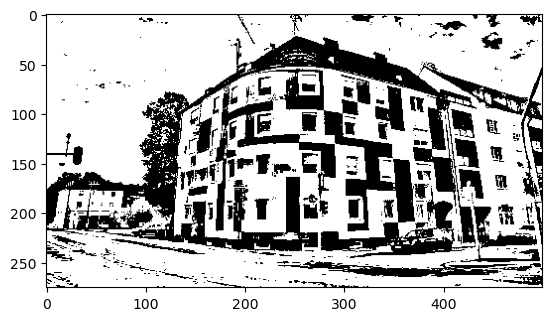

In [48]:
plt.imshow(house_threshold, cmap="gray");

In [49]:
%%time
hl_threshold = cv.adaptiveThreshold(gray_hl, #source
                                       255, #maximaler Wert
                                       cv.ADAPTIVE_THRESH_MEAN_C, #GAUSSIAN/MEAN
                                       cv.THRESH_BINARY, #_INV
                                       551, #Größe des ASB
                                       5) #Konstante, die abgezogen wird

CPU times: user 34.8 ms, sys: 6.77 ms, total: 41.6 ms
Wall time: 43.9 ms


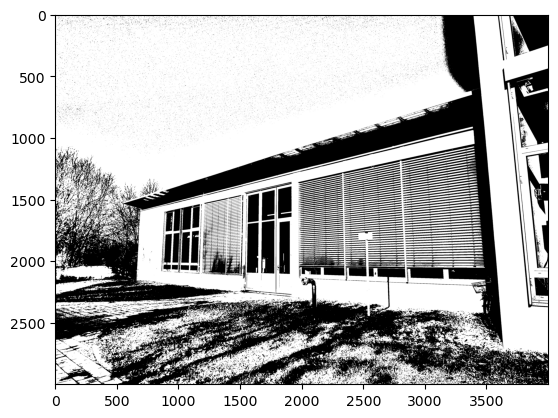

In [50]:
plt.imshow(hl_threshold, cmap="gray");

## Aufgabe 2

In [51]:
len(house.shape)

3

In [52]:
def compute_std(img, blocksize, name, save=False):

    if blocksize % 2 == 0:
        raise Exception("Die Blockgröße muss ungerade sein.")

    if len(img.shape) == 3: # Falls Farbbild, dann in Grauwertbild umwandeln
        img = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

    half_block = blocksize // 2

    height, width = img.shape # Größte Werte in jeder Dimension festlegen

    std = np.zeros((height, width), dtype = "float32") # Array, in dem die Ergebnisse gespeichert werden

    top_left = (0, 0)   # Koordianten der Eckpunkte festlegen 
    top_right = (0, width - 1)  # DA NUMPY IN DER FORM [Y, X] INDIZIERT SIND KOORDIANTEN VERTAUSCHT (NICHT [X, Y])!
    bottom_left = (height - 1, 0)
    bottom_right = (height - 1, width - 1)
    
    for y in range(height):  # Zeilenweise durch das Bild iterieren
        for x in range(width):

            y0 = max(0, y - half_block) # Größe des Blocks in X- und Y-Richtung ermitteln
            y1 = min(height, y + half_block + 1)

            x0 = max(0, x - half_block)
            x1 = min(width, x + half_block + 1)

            block = img[y0:y1, x0:x1]   # Block aus Bild ausschneiden
            _, stddev = cv.meanStdDev(block)    # Standardabweichung auf Block berechnen
            
    
            std[y, x] = stddev[0, 0]    # Wert der Standardabweichung in Array speichern
    
    if save:
        cv.imwrite(f"{name}_stddev_{blocksize}.tif", std)

    return std

In [53]:
%%time
stddev_7 = compute_std(house, 7, "house")

CPU times: user 492 ms, sys: 27.1 ms, total: 519 ms
Wall time: 287 ms


In [54]:
%%time
stddev_121 = compute_std(house, 121, "house")

CPU times: user 638 ms, sys: 0 ns, total: 638 ms
Wall time: 605 ms


In [55]:
ima_norma_7 = cv.normalize(stddev_7, None, 255, 0, cv.NORM_MINMAX, cv.CV_8UC1)
ima_norma_121 = cv.normalize(stddev_121, None, 255, 0, cv.NORM_MINMAX, cv.CV_8UC1)

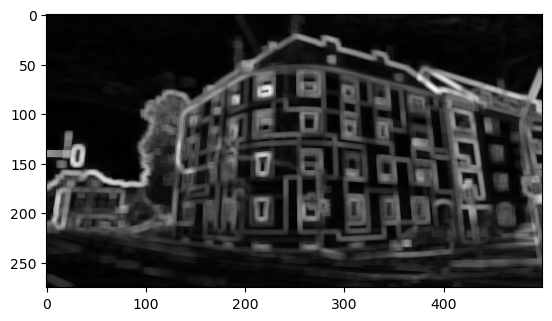

In [56]:
plt.imshow(ima_norma_7, cmap="gray");

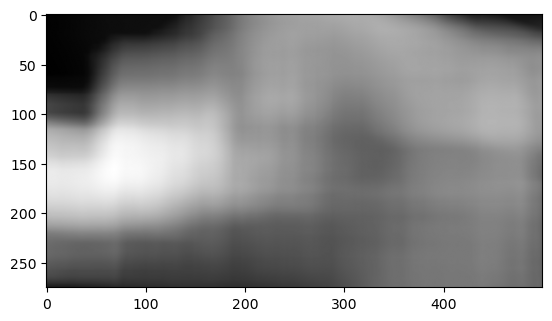

In [57]:
plt.imshow(ima_norma_121, cmap="gray");

### Implementierung mit ASBs

In [58]:
def compute_std_asb(img, blocksize, name, save=False):

    if blocksize % 2 == 0:
        raise Exception("Die Blockgröße muss ungerade sein.")
    
    if len(img.shape) == 3: #Falls Farbbild in Grauwertbild umwandeln
        img = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

    img = img.astype("float32") #Dtype ändern (Quadrierung)

    height, width = img.shape # Größte Werte in jeder Dimension festlegen
    std = np.zeros((height, width), dtype = "float32") # Array, in dem die Ergebnisse gespeichert werden

    asb, sq_asb = cv.integral2(img)  #Integralbild & quadriertes Integralbild von img

    half_block = blocksize // 2

    for y in range(height):  # Zeilenweise durch das Bild iterieren
        for x in range(width):

            y0 = max(0, y - half_block) # Größe des Blocks in X- und Y-Richtung ermitteln
            y1 = min(height, y + half_block + 1)

            x0 = max(0, x - half_block)
            x1 = min(width, x + half_block + 1)

            n_pixel = (x1 - x0) * (y1- y0) #Anzahl der Pixel im Block berechnen

            sum_asb = asb[y1, x1] - asb[y0, x1] - asb[y1, x0] + asb[y0, x0] #Wert aus ASB holen
            avg_asb = sum_asb / n_pixel #Durchschnittswert berechnen

            sum_sq_asb = sq_asb[y1, x1] - sq_asb[y0, x1] - sq_asb[y1, x0] + sq_asb[y0, x0] #Wert aus quadr. ASB holen
            ev_sq_asb = sum_sq_asb / n_pixel    #Erwartungswert berechnen

            stddev = (ev_sq_asb - avg_asb**2)**0.5 #Standardabweichung aus Erwartungswert & Durchschnitt

            std[y, x] = stddev 
    
    if save:
        cv.imwrite(f"{name}_stddev_ABS_{blocksize}.tif", std)

    return std

In [59]:
%%time
stddev_7_ASB = compute_std_asb(house, 7, "house")

CPU times: user 254 ms, sys: 0 ns, total: 254 ms
Wall time: 197 ms


In [60]:
%%time
stddev_121_ASB = compute_std_asb(house, 121, "house")

CPU times: user 260 ms, sys: 0 ns, total: 260 ms
Wall time: 203 ms


In [61]:
ima_norma_7_ASB = cv.normalize(stddev_7_ASB, None, 255, 0, cv.NORM_MINMAX, cv.CV_8UC1)
ima_norma_121_ASB = cv.normalize(stddev_121_ASB, None, 255, 0, cv.NORM_MINMAX, cv.CV_8UC1)

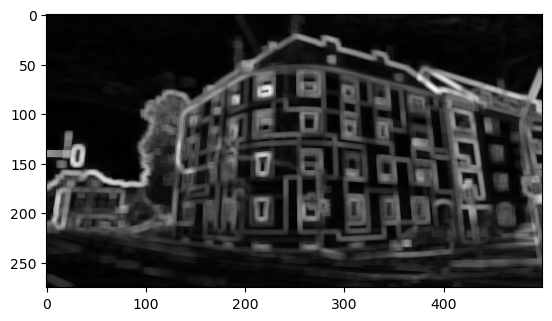

In [62]:
plt.imshow(ima_norma_7_ASB, cmap="gray");

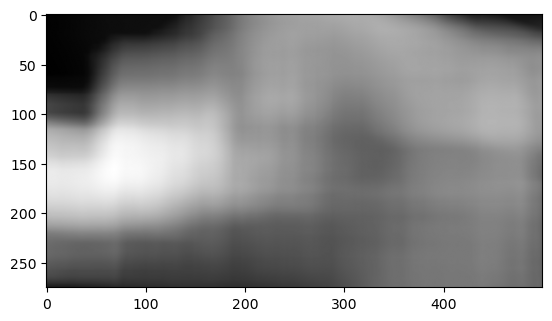

In [63]:
plt.imshow(ima_norma_121_ASB, cmap="gray");

In [64]:
def red_stddev(stddev, img, name, threshold, save=False):

    height, width = stddev.shape

    for y in range(height):
        for x in range(width):

            if stddev[y, x] > 50:
                img[y, x, 0] = 0
                img[y, x, 1] = 0
                img[y, x, 2] = 255

    if save:
        cv.imwrite(f"{name}_stddev>{threshold}_highlighted.tif", img) 

    return img

In [65]:
red_stddev(stddev_7_ASB, house, "house", 50, True)

array([[[225, 199, 183],
        [225, 199, 183],
        [223, 197, 181],
        ...,
        [193, 151, 114],
        [193, 151, 114],
        [194, 152, 115]],

       [[227, 201, 185],
        [227, 201, 185],
        [226, 200, 184],
        ...,
        [193, 151, 114],
        [194, 152, 115],
        [194, 152, 115]],

       [[229, 203, 187],
        [229, 203, 187],
        [229, 203, 187],
        ...,
        [194, 152, 115],
        [194, 152, 115],
        [194, 152, 115]],

       ...,

       [[ 88,  76,  70],
        [ 88,  76,  70],
        [ 89,  77,  71],
        ...,
        [117, 118, 122],
        [117, 118, 122],
        [112, 113, 117]],

       [[ 87,  75,  69],
        [ 87,  75,  69],
        [ 87,  75,  69],
        ...,
        [125, 126, 130],
        [125, 126, 130],
        [121, 122, 126]],

       [[ 85,  73,  67],
        [ 85,  73,  67],
        [ 85,  73,  67],
        ...,
        [127, 128, 132],
        [127, 128, 132],
        [123, 124, 128]]